# 02. Modelling for fault detection and diagnosis

**Framing.** The maintenance team wants three things. Is there a fault, which one is it, and how can wasted
visits be kept to a minimum? Only 28 labelled events exist, the labels are incomplete (they come from work orders), and each
AHU has its own normal operating point. The model therefore has three layers, each doing one job.

1. **Physics features** per row (setpoint error, outdoor-air fraction, coil ΔT, fan power against the affinity law).
2. **Normal-behaviour models.** Gradient-boosted regressors are fit on rows with no work order, one per
   signal for the whole fleet, with the AHU as a categorical input. They predict what valve, fan, mixed air,
   damper, CO2 and return air *should* be, and the residual is the fault evidence. This is what lets the
   approach work on a new AHU and absorbs unit-to-unit differences.
3. **A classifier on trailing windows** (3 h and 12 h medians of residuals and physics features) that
   outputs P(normal) and P(each fault). Windows only look backwards, so the same code runs live.

A causal **alarm state machine** turns probabilities into alarms. An alarm opens when the smoothed P(fault)
crosses a threshold and closes only after a sustained quiet period. Its type is the class with the highest
mean probability since the alarm opened, so the type does not flicker.

Pure rules would need separate thresholds for each of the 40 units, and a pure classifier on raw signals would
learn unit identity instead of faults. The hybrid keeps the physics explainable and lets the data set the thresholds.

## 0. Problem and success measures

**The problem.** The client runs 40 AHUs in an office, a hospital and a mall. Faults such as a stuck valve, a stuck damper,
a drifting sensor or a fouled coil keep the BMS running as if nothing happened, waste energy and are often found weeks
later after a complaint. The client wants faults found while they are happening, named correctly, and passed to the
maintenance team without burying the technicians in false alarms.

**What happens when an alarm fires.** The alarm becomes one ticket in the maintenance system with the AHU, the fault type,
the start time and the evidence chart. A technician visits and checks the named component (valve stroke, damper linkage,
supply-air sensor against a handheld probe, coil and isolation valve). The visit outcome becomes the label for the next
training run. A false alarm therefore costs a full wasted visit, and a wrong type sends the technician to the wrong part
of the unit, which costs time on site but still finds the unit faulty.

**How success is measured.** The brief scores events the way the maintenance team sees them, and this notebook uses the
same four numbers.

| Measure | Definition | Why it matters |
|---|---|---|
| Found | share of labelled events with at least one alarm row while the event is open | a missed fault keeps wasting energy |
| Right type | share of events where the most frequent alarm type inside the event is the true type | the technician goes to the right component |
| Delay | median hours from the labelled start to the first alarm | comfort complaints start within hours for some faults |
| False alarms | alarm runs that touch no labelled event, per AHU-month | each one is a wasted site visit |

For tuning, the four become one number, `J = right-type share − 4 × false alarms per AHU-month`. The weight of 4 is our
assumption, not the client's. It says that 0.05 false alarms per AHU-month (about 2 wasted visits a month across the
fleet) costs as much as missing the type on one fault in five.

**Today's baseline.** The buildings run a supply-air temperature alarm in the BMS, which says that something is wrong but
never what. A set of expert rules in the spirit of APAR (House et al., 2001) is the second baseline, standing in for what
an engineer would write by hand. Both go through the same alarm logic and scorer as the model in section 3b.

**Proposed targets, to be agreed with the client.** These are our proposal for the pilot, not targets the client has set.
The maintenance lead (fewer visits) and the energy manager (every fault found) will likely weigh them differently, and the
false-alarm weight in `J` is the place to settle that.

| Measure | Proposed target | Source of the number |
|---|---|---|
| Found | at least 80% of labelled faults | well above today's alarm, which finds about half (section 3b) |
| Right type | at least 70% | a technician who is sent to the right component three times in four saves a second trip |
| Delay | median under 24 hours | slow faults waste energy over days, fast ones are caught in hours |
| False alarms | at most 0.05 per AHU-month | about 2 wasted visits a month across 40 AHUs |
| Against today | better than the BMS alarm on found and false alarms, tested event by event | otherwise there is no reason to change |

**Out of scope.** Fault types other than the four labelled ones (fan belt, filter, chiller plant, zone faults), the energy
cost or severity of each fault, the root cause behind the component (why the valve stuck), any automatic change to the BMS
(the model only reads), filter replacement planning, detection faster than the 5-minute log, and new sensors. Requests in
these areas go onto a list for after the pilot rather than into this model.

**Time box.** The brief allows 48 hours for this analysis. The pilot plan, with its own gates, is in Q3 and Q4 of the report.

The next cell loads the libraries and the project code in `src/ahu_fdd` and sets the figure style.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ahu_fdd import pipeline as PL, features as F, events as E, experiments as X
from ahu_fdd.config import CLASSES, FAULTS, CODE_DIR

FIG = CODE_DIR.parent / "report" / "figures"
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

The next cell records the Python version, the library versions and the seed, so every number below can be
rebuilt with the same software.

In [2]:
import platform, importlib.metadata as im
SEED = 0  # classifier seed. The LightGBM regressors use the library's fixed default seed.
print("python", platform.python_version(), "| classifier seed", SEED, "| post-processing", PL.POST)
pd.Series({p: im.version(p) for p in ["pandas", "numpy", "pyarrow", "scikit-learn", "lightgbm", "scipy", "matplotlib"]}, name="version")

python 3.12.13 | classifier seed 0 | post-processing {'t_on': 0.8, 't_off': 0.3, 'smooth': 12, 'hold': 144}


pandas           3.1.1
numpy            2.5.4
pyarrow         26.0.1
scikit-learn     1.9.1
lightgbm         4.7.0
scipy           1.18.1
matplotlib      3.11.2
Name: version, dtype: str

The run uses Python 3.12.13 with pandas 3.1.1, numpy 2.5.4, pyarrow 26.0.1, scikit-learn 1.9.1, LightGBM 4.7.0
and scipy 1.18.1, the same versions pinned in `requirements.txt`. The classifier seed is 0 and the LightGBM regressors use
their fixed default seed. Running `run.py` twice gives the same `predictions.csv` byte for byte (same SHA-256 hash).

The next cell loads the raw log, applies every cleaning step from notebook 01 and prints the cleaning log,
so each fix is visible with its row count.

In [3]:
df, labels, log = PL.build_frame()
log[["issue", "building", "rows"]]

,issue,building,rows
0,clock shift (logger wrote UTC),B1,32153
1,duplicate export,B3,3439
2,"fan power in W, not kW",B3-AHU-04,6023
3,CO2 at 0 or 5000 ppm (sensor failure),B2-AHU-03,781
4,sat_c frozen (flatline),B2-AHU-08,2587
5,rat_c frozen (flatline),B1-AHU-07,2239
6,logging gap,B2,0


Every data-quality issue found in notebook 01 is fixed or masked before modelling. The biggest is the B1 clock shift (32,153 rows written in UTC), followed by B3-AHU-04's fan power in watts (6,023 rows) and the B3 duplicate export (3,439 rows). Frozen SAT and RAT sensors (2,587 and 2,239 rows) and the 781 impossible CO2 readings are masked, so the model never sees them as faults. The B2 logging gap removes no rows, because the gap itself is the missing data.

## 1. Normal-behaviour residuals (out of fold)

For train month *k*, the normal models are fit on every other month, minus a 2-day purge around
month *k* and minus any event that touches it. The test period uses models fit on all of January to June.

In [4]:
res = PL.residuals(df, labels)
w = PL.make_windows(df, res)
cols = F.feature_columns(w)
print(len(w), "steady running rows,", len(cols), "features")
clean = w[(w.split == "train") & (w.label == "normal") & ~w.near_event]
mae = {c: clean[c].abs().median() for c in F.RESID.values()}
by_class = w[w.split == "train"].groupby("label")[list(F.RESID.values())].median().round(2)
pd.Series(mae, name="median |residual| on normal rows").round(2).to_frame().T

1752625 steady running rows, 38 features


,r_valve,r_fan,r_mat,r_damper,r_co2,r_rat
median |residual| on normal rows,1.71,1.77,0.14,0.0,14.35,0.1


The normal models are trained on 1,752,625 steady running rows with 38 features. On normal rows the typical miss is 1.71 percentage points for the valve, 1.77 for fan power, 0.14 °C for mixed air and 14 ppm for CO2, which is small against the fault signatures in the next table. The damper residual has a median of exactly zero on normal rows, so any sustained non-zero value is already unusual.

In [5]:
by_class  # median residual by true label: the faults move exactly the residuals the physics predicts

,r_valve,r_fan,r_mat,r_damper,r_co2,r_rat
label,,,,,,
chw_valve_stuck,15.55,22.23,0.35,0.0,-16.95,1.73
low_coil_capacity,16.64,0.37,0.02,0.0,4.29,0.04
normal,0.00,0.01,-0.00,0.0,1.03,0.00
oa_damper_stuck,-1.52,-0.04,-0.54,40.0,577.80,-0.00
sat_sensor_bias,-6.58,8.18,-0.01,0.0,43.65,-0.00


Each fault moves the residuals the physics predicts, while normal rows sit at zero. A stuck valve leaves the valve 15.6 points off its expected position and pushes fan power 22.2 points up. Low coil capacity also pushes the valve 16.6 points open, but leaves the fan almost untouched (0.37), which is what separates the two. A stuck damper is the clearest case, with the damper residual at 40 and CO2 578 ppm above normal. Sensor bias is the subtlest, with the valve 6.6 points below expected and CO2 44 ppm high, which is why it is the slowest fault to confirm.

## 2. Validation scheme

* **Across time.** Leave-one-month-out on January to June with a 2-day purge, so neither the normal models nor
  the classifier see the scored month. Rolling windows are trailing only.
* **Across events.** An event that spans two months is removed from training in both folds.
* **Fuzzy edges.** Rows within 1 day of a labelled event that are not inside it are not used as
  "normal" for training, because start and end are estimates.
* **Metric from the maintenance team's view.** We count events found, events found with the right type, median
  delay from start to first alarm, and false alarms per AHU-month (an alarm run that touches no labelled
  event). Row-level accuracy is not reported, because the 95% normal rows dominate it.

Post-processing is tuned on the out-of-fold probabilities with
`J = typed recall − 4 × false alarms per AHU-month`.

In [6]:
oof = PL.oof_probabilities(w, df, labels, cols)
tr = w[w.split == "train"]; keys = tr[["ahu_id", "timestamp"]]
AHU_MONTHS = 40 * 6

grid = []
for t_on in [0.6, 0.7, 0.8, 0.9]:
    for smooth in [12, 36]:
        for hold in [36, 144]:
            s, _, _ = E.score_events(keys, E.alarms(oof, keys, t_on, 0.3, smooth, hold), labels, AHU_MONTHS)
            grid.append(dict(t_on=t_on, smooth=smooth, hold=hold, **s, J=E.objective(s)))
grid = pd.DataFrame(grid).sort_values("J", ascending=False)
grid[["t_on", "smooth", "hold", "detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month", "J"]].round(3).head(8)

,t_on,smooth,hold,detected,type_ok,median_delay_h,false_alarms,fa_per_ahu_month,J
8,0.8,12,36,27,22,9.333,2,0.008,0.752
9,0.8,12,144,27,22,9.333,2,0.008,0.752
4,0.7,12,36,27,22,8.833,3,0.012,0.736
5,0.7,12,144,27,22,8.833,3,0.012,0.736
2,0.6,36,36,27,21,11.750,1,0.004,0.733
3,0.6,36,144,27,21,11.750,1,0.004,0.733
6,0.7,36,36,27,21,12.250,1,0.004,0.733
7,0.7,36,144,27,21,12.250,1,0.004,0.733


The top of the table is flat. Thresholds 0.7 and 0.8 with 1-hour smoothing find the same 27 events with the same
22 correct types, and the hold time makes no difference. The 0.8 threshold has one false alarm fewer, while longer smoothing
costs a type and about 3 hours of delay. We use `t_on=0.8, t_off=0.3, smooth=12, hold=144` (`pipeline.POST`).
The longer hold is chosen for production because it keeps one fault from re-opening several tickets.

## 3. Results (out of fold, January to June)

In [7]:
pred = E.alarms(oof, keys, **PL.POST)
summary, ev, al = E.score_events(keys, pred, labels, AHU_MONTHS)
pd.Series(summary).round(3)

events              28.000
detected            27.000
type_ok             22.000
recall               0.964
typed_recall         0.786
median_delay_h       9.333
alarms              33.000
false_alarms         2.000
fa_per_ahu_month     0.008
dtype: float64

Out of fold, the model finds 27 of 28 labelled events (96%) and gives the right type for 22 (79%). Median delay from the labelled start to the first alarm is 9.3 hours. It opens 33 alarms in total, and only 2 of them touch no labelled event, which is 0.008 false alarms per AHU-month, or about one false visit per AHU every 10 years.

In [8]:
ev["pred_type"] = ev.pred_type.fillna("missed")
pd.crosstab(ev.fault_type, ev.pred_type, margins=True)

pred_type,chw_valve_stuck,low_coil_capacity,missed,oa_damper_stuck,sat_sensor_bias,All
fault_type,,,,,,
chw_valve_stuck,7,0,0,0,1,8
low_coil_capacity,1,5,0,0,1,7
oa_damper_stuck,0,0,1,6,0,7
sat_sensor_bias,1,1,0,0,4,6
All,9,6,1,6,6,28


The diagonal holds 22 of the 28 events. Stuck valves are the cleanest (7 of 8 right), and the damper fault is never confused with anything, though one of the 7 is missed. Sensor bias is the hardest, with 4 of 6 right and the other two called a stuck valve and low coil capacity. Low coil capacity loses one event each to a stuck valve and to sensor bias.

In [9]:
ev.groupby("fault_type").agg(events=("detected", "size"), detected=("detected", "sum"),
                             type_ok=("type_ok", "sum"), median_delay_h=("delay_h", "median")).round(1)

,events,detected,type_ok,median_delay_h
fault_type,,,,
chw_valve_stuck,8,8,7,2.0
low_coil_capacity,7,7,5,20.2
oa_damper_stuck,7,6,6,2.5
sat_sensor_bias,6,6,4,31.1


Speed depends on the fault. Stuck valves and damper faults are caught in a median of 2.0 and 2.5 hours, because they move the valve or the outdoor-air fraction at once. Low coil capacity (20.2 hours) and sensor bias (31.1 hours) build up slowly and need the 12-hour windows to show, which is acceptable for faults that waste energy over days rather than break comfort within hours.

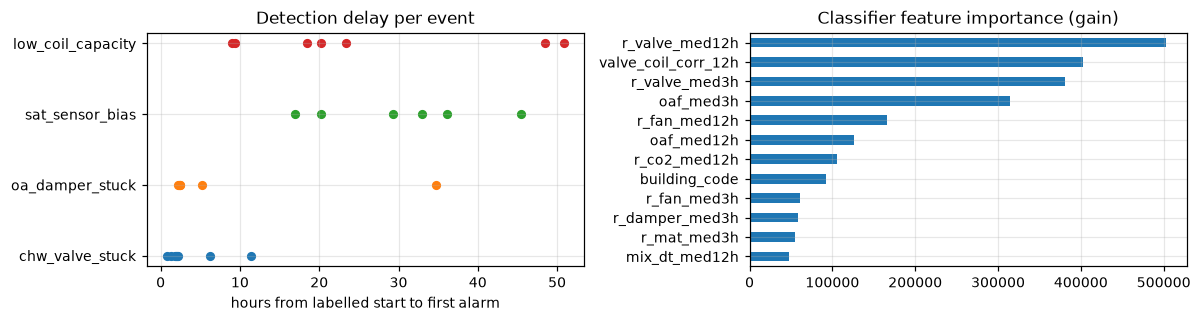

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for f in FAULTS:
    d = ev[(ev.fault_type == f) & ev.detected].delay_h
    ax[0].scatter(d, [f] * len(d), s=25)
ax[0].set_xlabel("hours from labelled start to first alarm"); ax[0].set_title("Detection delay per event")
imp = pd.Series(PL.fit_classifier(tr[cols], tr.label).booster_.feature_importance("gain"), index=cols)
imp.sort_values().tail(12).plot.barh(ax=ax[1]); ax[1].set_title("Classifier feature importance (gain)")
fig.tight_layout(); fig.savefig(FIG / "results.png", dpi=170)

The left chart shows the same split. All stuck-valve events and five of the six found damper events are caught within 12 hours, while the slow faults spread from 9 to 51 hours, with two low-coil-capacity events near 50 hours. Of the 27 found events, 20 are caught within a day. The right chart shows the classifier leans on the valve residual (3 h and 12 h), the valve-to-coil correlation and the outdoor-air fraction, which are exactly the physical signatures from notebook 01. The building code is only eighth, so the model is not just learning which building it is looking at.

## 3b. Is the model better than the simple alternatives?

Two baselines without machine learning go through the same alarm logic and the same event scorer. The first is the supply-air temperature alarm most building management systems already have. The second is a set of fleet-wide engineering rules, one per fault (`ahu_fdd/baseline.py`). The rule thresholds were picked on January to June itself, so this comparison flatters the rules, because the model is scored out of fold.

In [11]:
from ahu_fdd import baseline as B
methods = {"BMS SAT alarm (today)": B.bms_alarm(tr), "Expert rules": B.expert_rules(tr), "Model": oof}
scored = {}
for name, p in methods.items():
    s, e, _ = E.score_events(keys, E.alarms(p, keys, **PL.POST), labels, AHU_MONTHS)
    scored[name] = (s, e)
cmp_base = pd.DataFrame({k: v[0] for k, v in scored.items()}).T
cmp_base = cmp_base[["detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month"]].astype(float)
cmp_base.loc["BMS SAT alarm (today)", "type_ok"] = np.nan  # it never names a fault
cmp_base.round(3)

,detected,type_ok,median_delay_h,false_alarms,fa_per_ahu_month
BMS SAT alarm (today),14.0,NaN,2.875,8.0,0.033
Expert rules,19.0,10.0,2.583,9.0,0.038
Model,27.0,22.0,9.333,2.0,0.008


The model beats both baselines on everything except speed. The supply-air alarm that most buildings already run finds 14 of the 28 events (50%), names none of them, and raises 8 false alarms (0.033 per AHU-month). The expert rules find 19 events, type 10 correctly and raise 9 false alarms (0.038 per AHU-month), even with thresholds tuned on the same months they are scored on. The model finds 27, types 22 and raises 2, about four times fewer false visits than either baseline. The rules alarm sooner on average (2.6 against 9.3 hours), but mostly because the events they do catch are the fast ones, as the next cells show.

In [12]:
def with_ci(s, e):
    n = s["events"]
    d, t = E.proportion_ci(s["detected"], n), E.proportion_ci(s["type_ok"], n)
    m, f = E.median_ci(e.delay_h), E.rate_ci(s["false_alarms"], AHU_MONTHS)
    return {"found": f"{s['detected']}/{n} ({d[0]:.0%} to {d[1]:.0%})",
            "right type": f"{s['type_ok']}/{n} ({t[0]:.0%} to {t[1]:.0%})",
            "median delay h": f"{s['median_delay_h']:.1f} ({m[0]:.1f} to {m[1]:.1f})",
            "false alarms per AHU-month": f"{s['fa_per_ahu_month']:.3f} ({f[0]:.3f} to {f[1]:.3f})"}
pd.DataFrame({k: with_ci(*scored[k]) for k in ["Model", "Expert rules"]}).T

,found,right type,median delay h,false alarms per AHU-month
Model,27/28 (82% to 100%),22/28 (59% to 92%),9.3 (2.5 to 20.2),0.008 (0.001 to 0.030)
Expert rules,19/28 (48% to 84%),10/28 (19% to 56%),2.6 (2.2 to 3.4),0.037 (0.017 to 0.071)


With only 28 events every rate is uncertain, so the table adds 95% intervals (exact Clopper-Pearson for the counts, Poisson for the false-alarm rate, bootstrap for the median delay). The model finds between 82% and 100% of faults and types between 59% and 92%, against 48% to 84% and 19% to 56% for the rules. The typed-recall intervals do not overlap. The false-alarm intervals do overlap a little (0.001 to 0.030 for the model, 0.017 to 0.071 for the rules), so the gap there is likely but rests on few alarms.

In [13]:
m_ev, r_ev = scored["Model"][1], scored["Expert rules"][1]
both = m_ev.detected & r_ev.detected
paired = pd.DataFrame({
    "found": E.mcnemar_exact(m_ev.detected, r_ev.detected),
    "right type": E.mcnemar_exact(m_ev.type_ok, r_ev.type_ok)}).T
print("median delay on the", int(both.sum()), "events both methods find:",
      m_ev.delay_h[both].median().round(1), "h (model) vs", r_ev.delay_h[both].median().round(1), "h (rules)")
paired

median delay on the 19 events both methods find: 2.5 h (model) vs 2.6 h (rules)


,only_first,only_second,p_value
found,8.0,0.0,0.007812
right type,12.0,0.0,0.000488


Comparing the two methods event by event removes the luck of which events happen to exist. On the 19 events both methods find, the median delay is the same (2.5 hours for the model, 2.6 for the rules), so the model is not slower on the faults the rules can see. The model's longer overall median comes from the 8 extra faults that only the model finds. The model finds 8 events the rules miss and the rules find none the model misses (exact McNemar p = 0.008). For the right type the split is 12 to 0 (p = 0.0005). Both gaps are well beyond chance.

In [14]:
seed_rows = []
for seed in range(5):  # seed 0 is the run above; the residual models stay fixed
    p = oof if seed == 0 else PL.oof_probabilities(w, df, labels, cols, seed=seed)
    s, _, _ = E.score_events(keys, E.alarms(p, keys, **PL.POST), labels, AHU_MONTHS)
    seed_rows.append(dict(seed=seed, **s))
seeds = pd.DataFrame(seed_rows).set_index("seed")[["detected", "type_ok", "median_delay_h", "false_alarms"]]
json.dump({"baselines": {k: {m: float(x) for m, x in v[0].items()} for k, v in scored.items()},
           "seeds": seeds.reset_index().to_dict("records")},
          open(CODE_DIR / "outputs" / "baselines_and_seeds.json", "w"), indent=1, default=float)
pd.concat([seeds, seeds.agg(["mean", "std"]).round(2)])

,detected,type_ok,median_delay_h,false_alarms
0,27.0,22.00,9.333333,2.00
1,27.0,21.00,10.666667,3.00
2,27.0,21.00,11.000000,3.00
3,27.0,21.00,8.833333,3.00
4,27.0,21.00,10.916667,3.00
mean,27.0,21.20,10.150000,2.80
std,0.0,0.45,1.000000,0.45


Retraining the classifier with five different random seeds barely moves the result. Every seed finds 27 of 28 events. Typing is 22 for seed 0 and 21 for the other four (mean 21.2, standard deviation 0.45), median delay ranges from 8.8 to 11.0 hours (mean 10.2), and false alarms are 2 or 3 (mean 2.8). The reported seed-0 run is therefore on the good side of the spread by about one typed event and one false alarm, and the honest summary is "21 to 22 typed, 2 to 3 false alarms".

## 3c. Honest estimate, several comparisons and calibration

The post-processing in section 2 was tuned on the same six months it is scored on, which flatters the result a little.
The next cell repeats the tuning inside the folds (nested), so each month is scored with settings chosen on the other
five months only.

In [15]:
GRID = [(t, s, h) for t in [0.6, 0.7, 0.8, 0.9] for s in [12, 36] for h in [36, 144]]
month = tr.timestamp.dt.month
pred_by = {g: E.alarms(oof, keys, g[0], 0.3, g[1], g[2]) for g in GRID}
nested_pred, chosen = pd.Series("normal", index=tr.index, dtype=object), {}
for k in range(1, 7):
    inner = month != k  # tune on the other five months only
    J = {g: E.objective(E.score_events(keys[inner], p[inner], labels, 40 * 5)[0]) for g, p in pred_by.items()}
    chosen[k] = max(J, key=J.get)
    nested_pred[month == k] = pred_by[chosen[k]][month == k]
nested, nested_ev, _ = E.score_events(keys, nested_pred, labels, AHU_MONTHS)
print("chosen (t_on, smooth, hold) per held-out month:", chosen)
pd.DataFrame({"tuned in sample": summary, "nested (honest)": nested}).loc[
    ["detected", "type_ok", "median_delay_h", "alarms", "false_alarms", "fa_per_ahu_month"]].astype(float).round(3)

chosen (t_on, smooth, hold) per held-out month: {1: (0.6, 36, 36), 2: (0.8, 12, 36), 3: (0.8, 12, 36), 4: (0.8, 12, 36), 5: (0.9, 36, 36), 6: (0.8, 12, 36)}


,tuned in sample,nested (honest)
detected,27.000,27.000
type_ok,22.000,20.000
median_delay_h,9.333,11.250
alarms,33.000,36.000
false_alarms,2.000,2.000
fa_per_ahu_month,0.008,0.008


Tuned honestly, the model still finds 27 of 28 events with 2 false alarms (0.008 per AHU-month), but the right
type drops from 22 to 20 (71%, 95% interval 51% to 87%) and the median delay rises from 9.3 to 11.3 hours. Four of the six
months pick a 0.8 threshold with 1-hour smoothing, January picks 0.6 and May picks 0.9. Every month picks the 3-hour hold,
because the hold barely changes `J`. Production keeps the 12-hour hold so that one fault does not reopen several tickets.
The honest numbers to quote are 20 to 22 right types out of 28, and the report uses them.

The report makes three event-by-event claims against the baselines. Testing three claims raises the chance
that one of them passes by luck, so the next cell applies the Holm correction to the exact McNemar p-values.

In [16]:
b_ev = scored["BMS SAT alarm (today)"][1]
family = {"model vs rules, found": E.mcnemar_exact(m_ev.detected, r_ev.detected),
          "model vs rules, right type": E.mcnemar_exact(m_ev.type_ok, r_ev.type_ok),
          "model vs BMS alarm, found": E.mcnemar_exact(m_ev.detected, b_ev.detected)}
holm = pd.DataFrame(family).T.sort_values("p_value")
m = len(holm)  # Holm step-down. The i-th smallest p is multiplied by (m - i), then made monotone
holm["p_holm"] = (holm.p_value * np.arange(m, 0, -1)).cummax().clip(upper=1)
holm["significant_at_5pct"] = holm.p_holm < 0.05
holm

,only_first,only_second,p_value,p_holm,significant_at_5pct
"model vs BMS alarm, found",13.0,0.0,0.000244,0.000732,True
"model vs rules, right type",12.0,0.0,0.000488,0.000977,True
"model vs rules, found",8.0,0.0,0.007812,0.007812,True


All three claims survive the correction. The model finds 13 events the BMS alarm misses and the alarm finds
none that the model misses (Holm-adjusted p = 0.0007). Against the expert rules the split is 12 to 0 for the right type
(adjusted p = 0.001) and 8 to 0 for found events (adjusted p = 0.008). Each adjusted p is below 0.05, so none of the three
gaps comes from testing several things at once.

Technicians will see the probability next to each alarm, so it should mean what it says. The next cell compares
the predicted P(fault) with the observed share of fault rows in seven bins, leaving out the uncertain edges of events.

In [17]:
clean_rows = ~tr.near_event | (tr.label != "normal")  # the fuzzy edges of events have no reliable label
y = (tr.label != "normal")[clean_rows].astype(int)
p_fault = (1 - oof["normal"])[clean_rows]
brier, brier_ref = ((p_fault - y) ** 2).mean(), ((y.mean() - y) ** 2).mean()
bins = pd.cut(p_fault, [0, 0.05, 0.2, 0.4, 0.6, 0.8, 0.95, 1], include_lowest=True)
reliability = pd.DataFrame({"rows": y.groupby(bins, observed=False).size(),
                            "mean_P_fault": p_fault.groupby(bins, observed=False).mean(),
                            "observed_fault_share": y.groupby(bins, observed=False).mean()})
print(f"Brier score {brier:.4f}, against {brier_ref:.4f} for always predicting the base rate ({y.mean():.1%} fault rows)")
reliability.round(3)

Brier score 0.0048, against 0.0230 for always predicting the base rate (2.4% fault rows)


,rows,mean_P_fault,observed_fault_share
normal,,,
"(-0.001, 0.05]",1256065,0.000,0.002
"(0.05, 0.2]",2507,0.112,0.501
"(0.2, 0.4]",1404,0.292,0.745
"(0.4, 0.6]",1272,0.498,0.930
"(0.6, 0.8]",2098,0.709,0.979
"(0.8, 0.95]",4301,0.900,0.970
"(0.95, 1.0]",18396,0.995,0.950


The Brier score is 0.0048, against 0.0230 for always predicting the 2.4% base rate, a reduction of 79%.
Almost all rows (1,256,065) score below 0.05, and only 0.2% of them are faults. In the middle the model is underconfident.
Rows scored 0.05 to 0.2 are faults half of the time (50%), and rows scored 0.2 to 0.4 are faults 75% of the time. At the
top it is slightly overconfident (mean 0.995 against 95% observed). The alarm uses only the 0.8 threshold, and above it
95% to 97% of rows are real faults, so the ranking the alarm needs is sound. Before a probability is shown to technicians
it should be recalibrated (isotonic regression on the out-of-fold scores), which fits in the listening period of Q3.

## 4. Error analysis

In [18]:
ev[~ev.type_ok][["ahu_id", "fault_type", "start", "end", "detected", "delay_h", "pred_type"]]

,ahu_id,fault_type,start,end,detected,delay_h,pred_type
8,B1-AHU-05,low_coil_capacity,2025-03-03 16:20:00,2025-03-06 19:10:00,True,50.916667,chw_valve_stuck
9,B3-AHU-02,sat_sensor_bias,2025-03-06 03:05:00,2025-03-15 14:15:00,True,17.000000,chw_valve_stuck
11,B1-AHU-02,sat_sensor_bias,2025-03-26 11:45:00,2025-04-03 13:20:00,True,20.166667,low_coil_capacity
12,B3-AHU-02,low_coil_capacity,2025-03-29 16:50:00,2025-04-02 23:45:00,True,48.500000,sat_sensor_bias
14,B3-AHU-06,chw_valve_stuck,2025-04-13 20:25:00,2025-04-21 12:40:00,True,2.083333,sat_sensor_bias
17,B3-AHU-05,oa_damper_stuck,2025-04-20 16:25:00,2025-04-23 20:30:00,False,NaN,missed


Six events are missed or mistyped. **Half of them are on the three chronically saturated units**
(B1-AHU-05, B3-AHU-02, B3-AHU-09, see notebook 01), which are only 3 of the 40 AHUs. Their valve already sits at 100%, so low coil capacity cannot show as
more valve opening. It shows as SAT rising, which is also what a stuck-closed valve or a biased sensor
does. With one or two events per such unit, the classifier cannot separate them. The fix is a separate
"saturated unit" mode with its own features (SAT rise against CHW supply temperature and load), plus asking
the client to check these units, which are probably undersized or permanently fouled.

**Sensor bias against low coil capacity** (B1-AHU-02) and **stuck valve against sensor bias** (B3-AHU-06) are the other confusions. Both leave SAT on setpoint and move the
valve. The difference is in *how much cooling the air really gets*, which needs an independent
temperature (a discharge thermometer, or zone temperatures). In B2 the airflow station would help, and
this dataset has no zone temperatures.

**The missed damper fault (B3-AHU-05)** is in the mall, which has no CO2 sensor, so the damper command
does not react and the only evidence is a small change in mixed-air temperature over a short event.

**One of the two false alarms is an unlabelled fault.** The table below lists both, and the charts show the longer one.

       ahu_id fault_type               start                 end  rows  true_alarm
10  B1-AHU-11      fault 2025-04-22 11:30:00 2025-05-02 18:30:00  1086       False
26  B3-AHU-06      fault 2025-02-15 12:10:00 2025-02-16 15:25:00   201       False


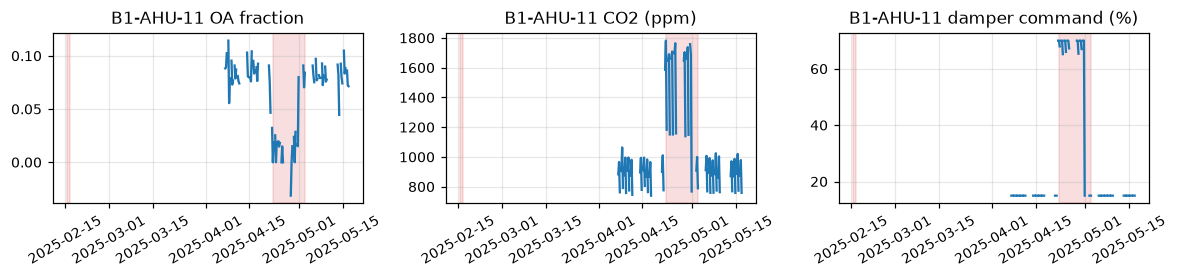

In [19]:
fa = al[~al.true_alarm]
print(fa)
x = w[(w.ahu_id == "B1-AHU-11") & w.timestamp.between("2025-04-07", "2025-05-19")]
fig, ax = plt.subplots(1, 3, figsize=(11, 2.6), sharex=True)
for a, c, t in zip(ax, ["oaf", "co2_ppm", "oa_damper_cmd_pct"], ["OA fraction", "CO2 (ppm)", "damper command (%)"]):
    s = x.set_index("timestamp")[c].resample("6h").median(); a.plot(s); a.set_title(f"B1-AHU-11 {t}")
    for r in fa.itertuples(): a.axvspan(r.start, r.end, color="tab:red", alpha=0.15)
    a.tick_params(axis="x", labelrotation=30)
fig.tight_layout(); fig.savefig(FIG / "unlabelled_damper.png", dpi=170)

The charts show B1-AHU-11 from 22 April to 5 May. Outdoor-air fraction drops from 0.08 to 0.02, CO2 climbs by about 650 ppm, and
the controller opens the damper command from 15% to 70% with no effect. This is a stuck damper with
no work order, which means the labels are incomplete. Counting it as correct leaves one false alarm in 240 AHU-months
(B3-AHU-06 in February, about one day long).

## 5. New AHU and fewer sensors

* **New AHU.** Hold out a quarter of the AHUs (stratified by building), fit the normal models and the
  classifier on the other units only, score the held-out ones, and repeat for all four quarters. This runs twice,
  (a) on day one with no history at all, and (b) after a 14-day listening period, where the normal models are
  refit with the new unit's first two healthy weeks (the classifier still never sees it, and the
  listening days are not scored).
* **Fewer sensors.** Re-run the out-of-fold evaluation with the CO2 residuals removed for every AHU
  (and the airflow indicator off). Airflow only enters through `flow_est`, which falls back to
  design airflow × fan speed, so CO2 is the sensor that matters.

In [20]:
exp = {"baseline": summary}
for name, drop in [("no CO2", ("co2",)), ("no CO2, no airflow", ("co2", "flow"))]:
    p, k = X.fewer_sensors(w, labels, drop)
    exp[name], _ = X.score(p, k, labels, AHU_MONTHS)
p, k = X.new_ahu(df, w, labels)
exp["new AHU, day one"], _ = X.score(p, k, labels, AHU_MONTHS)
p, k = X.new_ahu(df, w, labels, baseline_days=14)
exp["new AHU, after 14-day listening"], ev_new = X.score(p, k, labels, AHU_MONTHS * (1 - 14 / 181))
cmp = pd.DataFrame(exp).T[["detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month"]]
cmp.astype(float).round(3)

,detected,type_ok,median_delay_h,false_alarms,fa_per_ahu_month
baseline,27.0,22.0,9.333,2.0,0.008
no CO2,28.0,22.0,10.625,1.0,0.004
"no CO2, no airflow",27.0,21.0,10.083,2.0,0.008
"new AHU, day one",28.0,12.0,0.583,179.0,0.746
"new AHU, after 14-day listening",28.0,20.0,13.000,8.0,0.036


**Reading the table.** Losing CO2 costs almost nothing. With CO2 removed the model still finds all 28 events and types 22,
because the damper fault stays visible in the mixed-air temperature balance (outdoor-air fraction), and CO2 mainly makes it faster to confirm.
A building with fewer sensors therefore gets the same model with those inputs missing (LightGBM handles NaN
natively), not a separate model.

A brand-new AHU is the real risk. On day one every fault is still found, but the normal models do not
know the unit's own operating point. The result is 179 false alarms (0.75 per AHU-month), roughly 90
times the rate on known units, and only 12 of 28 types are right. Two weeks of listening (data collected,
nothing sent to technicians) brings false alarms down to 8 (0.036 per AHU-month) and typing up to 20 of 28.
That is the onboarding rule used in Q3 and the recommendation in Q4.

In [21]:
json.dump({k: {m: float(v) for m, v in s.items()} for k, s in exp.items()},
          open(CODE_DIR / "outputs" / "experiments.json", "w"), indent=1)
ev_new.groupby("fault_type")[["detected", "type_ok"]].sum()

,detected,type_ok
fault_type,,
chw_valve_stuck,8,7
low_coil_capacity,7,3
oa_damper_stuck,7,7
sat_sensor_bias,6,3


For a new AHU after listening, stuck valves (7 of 8) and damper faults (7 of 7) are typed almost as well as on known units. The loss is in low coil capacity (3 of 7) and sensor bias (3 of 6), the two faults that are defined against the unit's own normal capacity, which two weeks of history only partly teaches. Technicians should treat those two types as "check the coil and the sensor" during a new unit's first months.

## 6. Final model and predictions

Normal models and classifier are refit on all of January to June and applied to July and August with the tuned
post-processing. `run()` repeats the steps above end to end.

In [22]:
sub, clf, _ = PL.run()
print(sub.fault_type.value_counts())
r = E.runs(sub, sub.fault_type)
r[(r.end - r.start) > pd.Timedelta("6h")]

fault_type
normal               682880
sat_sensor_bias       11302
oa_damper_stuck        7394
chw_valve_stuck        6584
low_coil_capacity      3834
Name: count, dtype: int64


,ahu_id,fault_type,start,end,rows
0,B1-AHU-01,chw_valve_stuck,2025-07-07 13:45:00,2025-07-15 11:00:00,2266
1,B1-AHU-03,low_coil_capacity,2025-07-09 08:55:00,2025-07-15 10:15:00,1741
2,B1-AHU-09,low_coil_capacity,2025-07-14 18:10:00,2025-07-21 16:15:00,1988
3,B1-AHU-12,low_coil_capacity,2025-07-22 10:15:00,2025-07-22 19:00:00,105
4,B1-AHU-12,sat_sensor_bias,2025-07-22 19:05:00,2025-08-08 10:05:00,4775
5,B1-AHU-16,chw_valve_stuck,2025-07-23 11:10:00,2025-07-29 08:55:00,1697
6,B2-AHU-07,oa_damper_stuck,2025-07-30 02:25:00,2025-08-05 21:05:00,1951
7,B2-AHU-12,oa_damper_stuck,2025-07-13 03:15:00,2025-07-25 04:30:00,3463
8,B3-AHU-01,oa_damper_stuck,2025-08-21 12:20:00,2025-08-28 10:05:00,1980
9,B3-AHU-03,sat_sensor_bias,2025-07-25 16:05:00,2025-07-29 11:20:00,1095


On July and August, 29,114 of 711,994 rows (4.1%) are flagged as a fault, close to the 5% fault share in the training months. The final model raises 12 sustained alarms (longer than 6 hours), spread over all four fault types and all three buildings, for example a stuck valve on B1-AHU-01 from 7 to 15 July and a damper fault on B2-AHU-12 from 13 to 25 July. The 105-row low-coil-capacity alarm on B1-AHU-12 on 22 July turns into sensor bias the same evening, and should be read as one event of sensor bias.

In [23]:
import subprocess
r = subprocess.run([sys.executable, str(CODE_DIR / "starter" / "validate_submission.py"),
                      str(CODE_DIR.parent / "predictions.csv")], capture_output=True, text=True)
print(r.stdout, r.stderr[-2000:])
assert r.returncode == 0

OK: 711994 rows, format is valid
 


The starter validator accepts the file, which has 711,994 rows (one per AHU and 5-minute step in July and August) in the required format. This is the `predictions.csv` delivered with the report.

## 7. Behaviour tests

Good validation numbers do not prove that the model reacts to faults for the right reasons. The next cell edits 5,000
normal training rows in controlled ways. Directional tests push a fault signature into the inputs and expect the
probability of that fault to rise by more than 0.05. Invariance tests change something that should not matter (1% noise
on every reading, another building code) and expect a change below 0.02. The pass rules were fixed before the run.

In [24]:
probe = w[(w.split == "train") & (w.label == "normal") & ~w.near_event].sample(5000, random_state=0)
X0 = probe[cols]
def p_of(X, classes):
    return PL.predict_proba(clf, X)[classes].sum(axis=1).mean()
def edit(**set_to):
    X = X0.copy()
    for c, f in set_to.items():
        X[c] = f(X[c])
    return X
add = lambda v: (lambda s: s + v)
const = lambda v: (lambda s: s * 0 + v)
fault = list(FAULTS)
rng = np.random.default_rng(0)
num = [c for c in cols if c not in ("building_code", "has_co2", "has_flow")]
noisy = X0.copy(); noisy[num] = noisy[num] * (1 + rng.normal(0, 0.01, noisy[num].shape))
cases = [
    ("SAT 3 °C above setpoint for 12 h", "P(any fault)", fault,
     edit(sat_err_med3h=add(3), sat_err_med12h=add(3), sat_off_3h=const(1), sat_off_12h=const(1)), "up"),
    ("valve 30 points above its normal model", "P(valve stuck or low coil)", ["chw_valve_stuck", "low_coil_capacity"],
     edit(r_valve_med3h=add(30), r_valve_med12h=add(30)), "up"),
    ("no outdoor air arrives and CO2 builds up", "P(damper stuck)", ["oa_damper_stuck"],
     edit(oaf_med3h=const(0), oaf_med12h=const(0), r_co2_med3h=add(300), r_co2_med12h=add(300)), "up"),
    ("SAT 3 °C high while the valve is fully open (full signature)", "P(any fault)", fault,
     edit(sat_err_med3h=add(3), sat_err_med12h=add(3), sat_off_3h=const(1), sat_off_12h=const(1),
          valve_hi_3h=const(1), valve_hi_12h=const(1), r_valve_med3h=add(30), r_valve_med12h=add(30)), "up"),
    ("no outdoor air, CO2 up, controller opens the damper (full signature)", "P(damper stuck)", ["oa_damper_stuck"],
     edit(oaf_med3h=const(0), oaf_med12h=const(0), r_co2_med3h=add(300), r_co2_med12h=add(300),
          r_damper_med3h=add(30), r_damper_med12h=add(30)), "up"),
    ("1% random noise on every reading", "P(any fault)", fault, noisy, "same"),
    ("same rows labelled as another building", "P(any fault)", fault,
     edit(building_code=lambda s: s % 3 + 1), "same"),
]
rows = []
for name, metric, cls, X, expect in cases:
    before, after = p_of(X0, cls), p_of(X, cls)
    ok = after > before + 0.05 if expect == "up" else abs(after - before) < 0.02
    rows.append(dict(test=name, metric=metric, before=before, after=after, expected=expect, passed=ok))
alarm_flip = ((1 - PL.predict_proba(clf, noisy)["normal"] > 0.8) != (1 - PL.predict_proba(clf, X0)["normal"] > 0.8)).mean()
print(f"ahu_id or timestamp among the inputs: {bool({'ahu_id', 'timestamp'} & set(cols))}. "
      f"Rows crossing the 0.8 alarm threshold under 1% noise: {alarm_flip:.2%}")
pd.DataFrame(rows).round(3)

ahu_id or timestamp among the inputs: False. Rows crossing the 0.8 alarm threshold under 1% noise: 0.02%


,test,metric,before,after,expected,passed
0,SAT 3 °C above setpoint for 12 h,P(any fault),0.0,0.048,up,False
1,valve 30 points above its normal model,P(valve stuck or low coil),0.0,0.753,up,True
2,no outdoor air arrives and CO2 builds up,P(damper stuck),0.0,0.024,up,False
3,SAT 3 °C high while the valve is fully open (f...,P(any fault),0.0,0.981,up,True
4,"no outdoor air, CO2 up, controller opens the d...",P(damper stuck),0.0,0.205,up,True
5,1% random noise on every reading,P(any fault),0.0,0.001,same,True
6,same rows labelled as another building,P(any fault),0.0,0.000,same,True


Five of the seven tests pass and two fail, and the failures say something useful about the model. A single symptom on its own barely moves it. Pushing SAT 3 °C above setpoint for 12 hours raises P(any fault) from 0.000 to only 0.048, and removing outdoor air with CO2 rising raises P(damper stuck) to only 0.024, both below the 0.05 rule. When the same symptoms come with the rest of their physical signature, the model reacts strongly. SAT high with the valve fully open gives 0.981, and no outdoor air with CO2 up and the controller opening the damper gives 0.205. A raised valve residual alone gives 0.753 for a valve or coil fault. The invariance tests pass cleanly, since 1% noise moves P(any fault) by 0.001, a different building code moves it by less than 0.001, and only 0.02% of rows cross the 0.8 alarm threshold under noise. Neither `ahu_id` nor the timestamp is an input.

The model therefore waits for a consistent signature rather than reacting to one reading, which is what keeps false alarms at 2 in 240 AHU-months. The cost is that a fault which shows only one symptom (for example a damper fault in a building without CO2, like the missed B3-AHU-05 event) is caught late or not at all. The pilot should keep the BMS supply-air alarm running alongside the model for exactly this case.

## 8. What it means for the maintenance team

The next cell turns the honest (nested) results into what each building's team would see, which is events found, right
types and wasted visits per year, and compares the wasted visits with today's alarm and the expert rules.

In [25]:
units = pd.Series({"B1": 16, "B2": 12, "B3": 12})
def per_building(ev_, al_):
    b_ev, b_fa = ev_.ahu_id.str[:2], al_[~al_.true_alarm].ahu_id.str[:2]
    t = pd.DataFrame({"AHUs": units, "events": ev_.groupby(b_ev).size(), "found": ev_.groupby(b_ev).detected.sum(),
                      "right type": ev_.groupby(b_ev).type_ok.sum(), "false alarms": b_fa.value_counts()}).fillna(0)
    t["false visits per year"] = t["false alarms"] * 2  # six scored months, so twice per year
    return t
_, _, al_rules = E.score_events(keys, E.alarms(methods["Expert rules"], keys, **PL.POST), labels, AHU_MONTHS)
_, _, al_bms = E.score_events(keys, E.alarms(methods["BMS SAT alarm (today)"], keys, **PL.POST), labels, AHU_MONTHS)
_, _, al_nested = E.score_events(keys, nested_pred, labels, AHU_MONTHS)
by_building = per_building(nested_ev, al_nested)
by_building.loc["fleet"] = by_building.sum()
visits = pd.DataFrame({name: [a[~a.true_alarm].shape[0] * 2] for name, a in
                       [("BMS SAT alarm", al_bms), ("Expert rules", al_rules), ("Model (nested)", al_nested)]},
                      index=["false visits per year, whole fleet"])
display(by_building.astype(int))
visits

,AHUs,events,found,right type,false alarms,false visits per year
B1,16,10,10,8,1,2
B2,12,6,6,6,0,0
B3,12,12,11,6,1,2
fleet,40,28,27,20,2,4


,BMS SAT alarm,Expert rules,Model (nested)
"false visits per year, whole fleet",16,18,4


Every building gets almost all of its faults found (10 of 10 in B1, 6 of 6 in B2, 11 of 12 in B3). Typing is
perfect in the hospital (6 of 6) and weakest in the mall (6 of 12), which has no CO2 sensor and holds two of the three
saturated units. Across the fleet the model would cause about 4 wasted visits a year, against 16 for the BMS alarm and 18
for the expert rules, while finding 27 faults instead of 14 or 19. Wasted visits are false alarms in six months times two,
which assumes that the second half of the year looks like the first.

**Decision.** The recommendation is a pilot, not a full rollout. On the honest estimate the model meets every
proposed target from section 0 (found 96% against 80%, right type 71% against 70%, median delay 11.3 hours against 24,
false alarms 0.008 against 0.05 per AHU-month) and beats the BMS alarm event by event. The right-type margin is thin, with
a 95% interval of 51% to 87%, so the pilot starts in listening mode and sends tickets building by building (Q3 and Q4).
The saturated units B1-AHU-05, B3-AHU-02 and B3-AHU-09 get their alarms as "check the unit" without a fault type until a
separate saturated-unit mode is built.

**Fairness and personal data.** The data holds no personal data and the model makes no decision about people. It ranks
equipment for inspection. Fairness checks between groups of people and UU PDP therefore do not apply. The comparable check
is between buildings, and the table above shows that the mall is served worse on fault type, which is the segment to
watch in the pilot.

## 9. Model bundle and experiment log

The next cell saves the final normal models, classifier, feature list and post-processing as one bundle, with a readable
`bundle.json` that records where the bundle came from (data hashes, code commit, library versions, seed and evaluation).

In [26]:
import hashlib, subprocess, joblib
from datetime import datetime, timezone
from ahu_fdd.config import DATA_DIR
BUNDLE = CODE_DIR / "outputs" / "model"; BUNDLE.mkdir(parents=True, exist_ok=True)
clean_normal = df.steady & (df.label == "normal") & ~df.near_event
normal_models = F.NormalModels(df.ahu_id.unique()).fit(df[clean_normal])  # same fit as inside run()
joblib.dump({"normal_models": normal_models, "classifier": clf, "features": cols, "post": PL.POST}, BUNDLE / "bundle.joblib")
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()[:16]
data_files = ["ahu_train.parquet", "ahu_test.parquet", "fault_labels_train.csv", "ahu_metadata.csv"]
git = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=CODE_DIR, capture_output=True, text=True).stdout.strip()
meta_bundle = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "code_commit": git or "unknown",
    "data_sha256_16": {f: sha(DATA_DIR / f) for f in data_files},
    "libraries": {p: im.version(p) for p in ["pandas", "numpy", "pyarrow", "scikit-learn", "lightgbm", "scipy"]},
    "seed": SEED, "post_processing": PL.POST, "classifier_params": PL.CLF_PARAMS, "normal_model_params": F.LGB_PARAMS,
    "features": cols, "classes": CLASSES,
    "evaluation_oof_jan_jun": {"tuned_in_sample": {k: float(v) for k, v in summary.items()},
                               "nested": {k: float(v) for k, v in nested.items()}},
    "predictions_sha256_16": sha(CODE_DIR.parent / "predictions.csv"),
}
json.dump(meta_bundle, open(BUNDLE / "bundle.json", "w"), indent=1)
print(f"bundle.joblib {(BUNDLE / 'bundle.joblib').stat().st_size / 1e6:.1f} MB, bundle.json written")
pd.Series({k: v for k, v in meta_bundle.items() if isinstance(v, str)} | meta_bundle["data_sha256_16"])

bundle.joblib 5.3 MB, bundle.json written


created_utc               2026-11-10T09:28:26+00:00
code_commit                                 ffea4b8
predictions_sha256_16              f19ade444892bc66
ahu_train.parquet                  58daad558b7b2ceb
ahu_test.parquet                   ceb2d9c0080cd974
fault_labels_train.csv             09d0de7e1a6fcd5c
ahu_metadata.csv                   8a86fceed3259a27
dtype: str

The bundle is 5.3 MB. The JSON pins the four input files by hash (training data `58daad558b7b2ceb`, test data `ceb2d9c0080cd974`), the library versions, the seed, the post-processing and the hash of `predictions.csv` (`f19ade444892bc66`, the same file `run.py` rebuilds). A later run can therefore prove that it used the same data and code, and rolling back means loading the previous bundle, which takes seconds.

The next cell writes every run made in this notebook into one experiment log, stamped with the data hash and
the code commit, and summarises it by kind.

In [27]:
METRICS = ["detected", "type_ok", "median_delay_h", "false_alarms", "fa_per_ahu_month"]
log_rows = [dict(experiment=f"tuning t_on={r.t_on} smooth={r.smooth} hold={r.hold}", kind="post-processing grid",
                 **r[METRICS].to_dict()) for _, r in grid.iterrows()]
for name, (s, _) in scored.items():
    log_rows.append(dict(experiment=name, kind="baseline vs model", **{k: s[k] for k in METRICS}))
for seed, r in seeds.iterrows():
    log_rows.append(dict(experiment=f"classifier seed {seed}", kind="seed spread", **r.to_dict()))
for name, s in exp.items():
    log_rows.append(dict(experiment=name, kind="new AHU and sensors", **{k: s[k] for k in METRICS}))
log_rows.append(dict(experiment="nested post-processing tuning", kind="honest estimate", **{k: nested[k] for k in METRICS}))
experiment_log = pd.DataFrame(log_rows).assign(data=meta_bundle["data_sha256_16"]["ahu_train.parquet"], commit=meta_bundle["code_commit"])
experiment_log.to_csv(CODE_DIR / "outputs" / "experiment_log.csv", index=False)
print(len(experiment_log), "experiments logged")
experiment_log.groupby("kind").agg(runs=("experiment", "size"), best_type_ok=("type_ok", "max"), fewest_false_alarms=("false_alarms", "min"))

30 experiments logged


,runs,best_type_ok,fewest_false_alarms
kind,,,
baseline vs model,3,22.0,2.0
honest estimate,1,20.0,2.0
new AHU and sensors,5,22.0,1.0
post-processing grid,16,22.0,1.0
seed spread,5,22.0,2.0


The log holds 30 runs, made up of 16 post-processing settings, 3 methods compared, 5 classifier seeds, 5 experiments on new AHUs and missing sensors, and the nested estimate. The best right-type count anywhere in the log is 22 and the honest nested estimate is 20, which is the gap to keep in mind when a single number is quoted. The fewest false alarms (1) come from the run without CO2 and from one grid setting, never from a setting that also keeps 22 right types.

**Promotion of a new version.** A challenger replaces the champion only after two gates. The first is a replay
on the labelled months, compared event by event with the McNemar test as in section 3b. The second is a shadow run on the
fleet. A one-week shadow on 40 AHUs covers about 9 AHU-months, where fewer than one false alarm is expected, so it cannot
tell two versions apart. With no unconfirmed alarm in 30 AHU-months, the 95% upper bound on the false-alarm rate is 3/30,
or 0.1 per AHU-month, which takes a little over three weeks on 40 AHUs. Rollback means loading the previous bundle.

## 10. Monitoring plan

The next cell measures input drift with the population stability index (PSI) for the ten most important features plus
outdoor and chilled-water temperature, comparing January to June with July and August. Each value is read against the
largest PSI seen between two training months, because some features swing a lot even without a fault. It also compares
the share of rows in alarm.

In [28]:
def psi(a, b, bins=10):
    a, b = a.dropna(), b.dropna()
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    pa = np.clip(np.histogram(a, edges)[0] / len(a), 1e-4, None)
    pb = np.clip(np.histogram(b, edges)[0] / len(b), 1e-4, None)
    return float(((pb - pa) * np.log(pb / pa)).sum())
imp = pd.Series(clf.booster_.feature_importance("gain"), index=cols).sort_values(ascending=False)
watch = list(imp.index[:10]) + ["oat_c", "chwst_c"]
train_w, test_w = w[w.split == "train"], w[w.split == "test"]
mon = pd.DataFrame({
    "PSI Jan-Jun vs Jul-Aug": {c: psi(train_w[c], test_w[c]) for c in watch},
    "largest PSI between training months": {c: max(psi(train_w.loc[train_w.month != k, c], train_w.loc[train_w.month == k, c]) for k in range(1, 7)) for c in watch},
})
mon["status"] = pd.cut(mon["PSI Jan-Jun vs Jul-Aug"], [-1, 0.2, 0.3, np.inf], labels=["ok", "watch", "serious"])
live = test_w[["ahu_id", "timestamp"]].merge(sub, on=["ahu_id", "timestamp"], how="left")
alarm_share = pd.Series({"Jan-Jun out of fold": (pred != "normal").mean(), "Jul-Aug live": (live.fault_type != "normal").mean()})
print("share of rows in alarm:", alarm_share.round(4).to_dict())
mon.round(3)

share of rows in alarm: {'Jan-Jun out of fold': 0.0253, 'Jul-Aug live': 0.0378}


,PSI Jan-Jun vs Jul-Aug,largest PSI between training months,status
r_valve_med12h,0.022,0.087,ok
valve_coil_corr_12h,0.001,0.010,ok
r_valve_med3h,0.008,0.027,ok
oaf_med3h,0.001,0.003,ok
r_fan_med12h,0.055,0.007,ok
oaf_med12h,0.001,0.007,ok
r_co2_med12h,0.223,0.255,watch
building_code,0.000,0.005,ok
r_fan_med3h,0.034,0.005,ok
r_damper_med12h,0.074,0.773,ok


Eleven of the twelve watched inputs are stable, with PSI at most 0.074. The one in watch is the 12-hour CO2 residual at 0.223, but training months already differ from each other by up to 0.255 on the same feature, so this is the normal swing of occupancy rather than new drift. The fan-power residuals are small (0.055 and 0.034) but larger than anything seen between training months (0.007 and 0.005), which fits filters loading up through the year and is the first input to watch in the pilot. Outdoor temperature (0.013) and chilled-water temperature (0.002) barely move. The damper residual has a large PSI between training months (0.773) because it sits at exactly zero most of the time and its bins are unstable, so its monitor should track the share of non-zero rows instead. The share of rows in alarm rises from 2.5% out of fold to 3.8% in July and August, in line with the 12 sustained alarms in section 6.

The alarms that keep the model honest after go-live are listed below. Retraining is triggered by these events,
not only by the calendar, and every retrained version still passes both promotion gates in section 9.

| Signal | Watch | Act | Response |
|---|---|---|---|
| Input drift (PSI on the 12 watched inputs) | above 0.2 and above the largest PSI between training months | above 0.3 in more than one building | check sensors and schedules, retrain if the change is real |
| Precision on confirmed tickets | more than 5 points below the previous quarter | 4 weeks in a row | review the false alarms, retrain with the new labels |
| Share of rows in alarm | above 6% | above 8% for a week | look for a plant-wide change before blaming the model |
| New confirmed faults | 10 since the last fit | | scheduled retrain |
| Scoring job | batch more than 15 minutes late or failing | twice in one day | page the engineer on call, alarms keep their last state |
| Setpoint or schedule change on an AHU | any change | | 14-day listening refit of the normal models for that AHU |

## 11. Conclusions, decision and limitations

**Findings.** On January to June, scored out of fold with the alarm thresholds tuned inside the folds, the model finds 27 of 28 labelled faults (95% interval 82% to 100%), names 20 correctly (51% to 87%) and raises 2 false alarms in 240 AHU-months. With thresholds tuned on the scored months it names 22, and across five seeds 21 or 22. Median delay is 11.3 hours, with stuck valves and damper faults caught in about 2 hours and slow coil and sensor faults in about a day. It beats today's BMS alarm (14 found, 8 false alarms) and the expert rules (19 found, 10 named, 9 false alarms), and all three event-by-event gaps survive the Holm correction. For the maintenance team this means about 4 wasted visits a year across the fleet instead of 16 today.

**Decision.** Go to a pilot in listening mode, then send tickets building by building as described in Q3 and Q4. Send alarms on the three saturated units without a fault type until a separate mode exists, and keep the BMS supply-air alarm running alongside the model.

**Limitations.**

* Only 28 labelled events exist, so one more or one fewer right type moves the share by 4 points.
* Labels are incomplete. One of the two false alarms is an unlabelled stuck damper, so the real false-alarm rate may be lower and the real miss rate is unknown.
* The expert-rule thresholds were tuned on the months they are scored on, which favours the rules rather than the model.
* The three chronically saturated units hold half of the six errors.
* There are no zone temperatures and airflow is measured only in B2, so low coil capacity and sensor bias stay hard to tell apart.
* The model needs a consistent signature (section 7), so a fault with only one visible symptom is caught late.
* A new AHU needs 14 days of listening (179 false alarms on day one, 8 after listening).
* Predicted probabilities are underconfident between 0.05 and 0.6 and need recalibration before technicians see them.
* July and August carry no labels, so the test-period numbers are alarm counts, not accuracy.